# **PageRank**
PageRank is an algorithm originally developed by Google to evaluate the
**importance** of **webpages** by analysing the structure of hyperlinks between them.
The underlying idea is that a **page becomes important if it is referenced by
other important pages**, so relevance propagates through the network.

**Weighting scheme**

The score $x_k$ of a page $k$ is defined as:


$$x_k = \sum_{j \in L_k} \frac{x_j}{n_j}$$

where $L_k$ is the set of pages linking to $k$, $x_j$ is the score of the source page $j$, $n_j$ is the number of outgoing links from page $j$.

This formula implies that a page's score is maximized when it receives links from important sources that have a low out-degree, as the "vote" is not diluted among many targets.

Because each page contributes to the importance of the pages it points to,
the definition of PageRank is inherently recursive.
When this dependency is
written simultaneously for all pages, it leads to the fixed-point equation


$$A x = x$$

where $A$ is the link matrix and $x$ represents the PageRank vector.


---

In [ ]:
import numpy as np
from fractions import Fraction
from numpy.linalg import eig
from IPython.display import Image, display


In [ ]:
def print_ranking(title, scores, pages=None, urls=None, top=None):
    """
    Function to print the ranking of pages.
    """
    # Ensure scores is a 1D numpy array of floats
    scores = np.asarray(np.real(scores), dtype=float).ravel()
    if pages is None:
        pages = np.arange(1, len(scores) + 1)
    else:
        pages = np.asarray(pages, dtype=int).reshape(-1)
    #build and sort list of tuples (score, page)
    ranking = list(zip(scores, pages))
    ranking.sort(reverse=True, key=lambda x: x[0]) #sort based on score
    if top is not None: #for the ranking of Hollins.dat, we just want to print the "top" pages
        ranking = ranking[:top]

    #cosntruction of the table
    width = 46 if urls is None else 80
    print("\n" + title)
    print("-" * width)
    #header
    header = f"{'Rank':<6} {'Page':<6} {'Score':<12}"
    if urls is not None:
        header += " URL" #in the case of Hollins.dat we also want to show the urls of the pages in the print
    print(header)
    print("-" * width)
    #rows
    for rank_i, (score, page) in enumerate(ranking, start=1):
        if urls is None:
            print(f"{rank_i:<6} {page:<6} {score:<12.6f}")
        else:
            print(f"{rank_i:<6} {page:<6} {score:<12.6f} {urls[page-1]}")
    print("-" * width)

---

##**Exercise 1**
*Suppose the people who own page 3 in the web of Figure 1 are infuriated by the fact that its importance score, computed using formula (2.1), is lower than the score of page 1. In an attempt to boost page 3’s score, they create a page 5 that links to page 3; page 3 also links to page.*

The goal of this exercise is to understand how the PageRank **score** of a page can be **influenced** by modifying the link structure of the network.
Specifically, we analyze how the introduction of a new page (Page 5) and a reciprocal link can boost the importance of Page 3.




**New Graph**

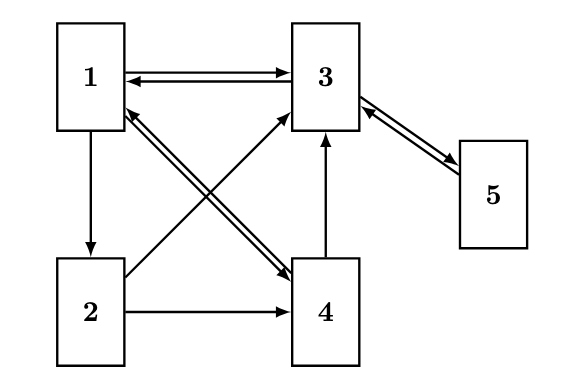

In [ ]:
display(Image(filename='exercise1_graph.png',width=400,height=300))

In [ ]:
A=np.array([
    [0.0, 0.0, 1/2, 1/2, 0.0],
    [1/3, 0.0, 0.0, 0.0, 0.0],
    [1/3, 1/2, 0.0, 1/2,1.0],
    [1/3, 1/2, 0.0, 0.0,0.0],
    [0.0, 0.0, 1/2, 0.0,0.0]
])
print("Matrix Exercise 1 (with Page 5):")
display(A)

Matrix Exercise 1 (with Page 5):


array([[0.        , 0.        , 0.5       , 0.5       , 0.        ],
       [0.33333333, 0.        , 0.        , 0.        , 0.        ],
       [0.33333333, 0.5       , 0.        , 0.5       , 1.        ],
       [0.33333333, 0.5       , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.5       , 0.        , 0.        ]])

In [ ]:
def compute_rank(A):
  """
  Computes the rank of a link matrix A using the eigenvectos given by the eig method.
  """
  autovalori, autovettori = eig(A)
  score=autovettori[:,0]
  score_normalized=score/score.sum()
  score_rounded = np.round(score_normalized, 4)
  ranked_pages = []
  for i, s in enumerate(score_rounded):
      pagina_label = f"x{i+1}"
      ranked_pages.append((s, pagina_label))
  ranked_pages.sort(key=lambda item: item[0], reverse=True)
  return score_rounded,ranked_pages


**Final Rank with Page 5**

In [ ]:
#with the added page 5, the position of page 3 rises
score_normalized,ranked_pages=compute_rank(A)
print_ranking("Rank Results — Fig. 2.1 with Page 5", score_normalized, pages=np.arange(1,6))


Rank Results — Fig. 2.1 with Page 5
----------------------------------------------
Rank   Page   Score       
----------------------------------------------
1      3      0.367300    
2      1      0.244900    
3      5      0.183700    
4      4      0.122400    
5      2      0.081600    
----------------------------------------------


**Original Rank without Page 5**

For the purpose of the excercise, we also compute the rank of Fig 2.1 WITHOUT the added page, in order to show the difference.

In [ ]:
A_2_1 = np.array([
    [0.0, 0.0, 1, 1/2],
    [1/3, 0.0, 0.0, 0.0],
    [1/3, 1/2, 0.0, 1/2],
    [1/3, 1/2, 0.0, 0.0]
])
score_normalized,ranked_pages=compute_rank(A_2_1) #Calcolo score e rank con eigenvector per M
print_ranking("Rank Results — Fig. 2.1 without Page 5", score_normalized, pages=np.arange(1,6))



Rank Results — Fig. 2.1 without Page 5
----------------------------------------------
Rank   Page   Score       
----------------------------------------------
1      1      0.387100    
2      3      0.290300    
3      4      0.193500    
4      2      0.129000    
----------------------------------------------


**Results**

In the specific configuration considered in this exercise, Page 5 has a single outgoing link pointing to page 3, so its entire PageRank contribution is transferred to page 3. Since
page 3 also links back to page 5, this mutual reinforcement increases the score of page 3.

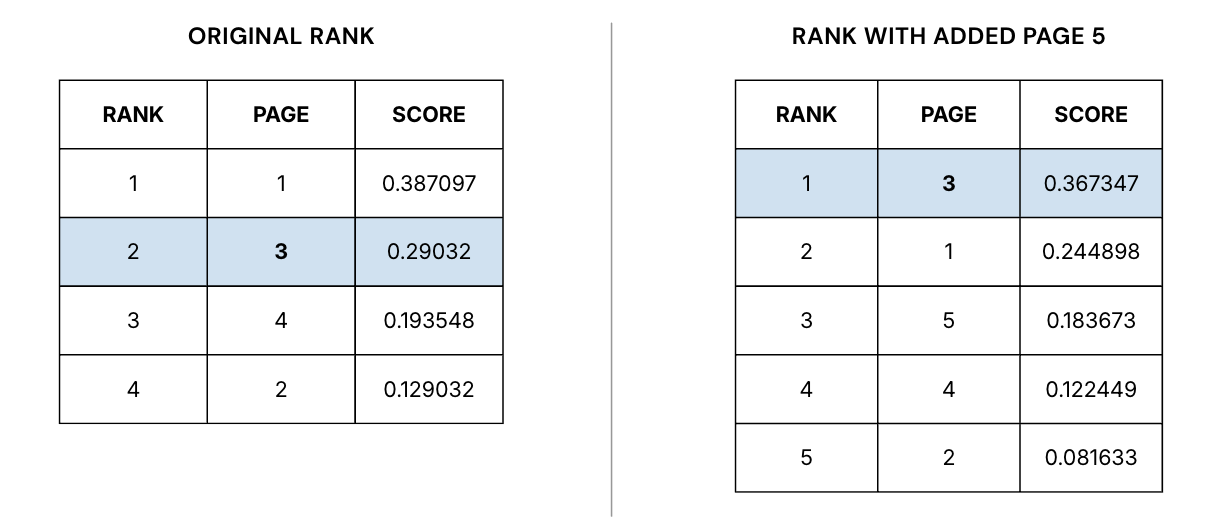

In [ ]:
display(Image(filename='rank_es1.png',width=850, height=400))



---

## **Exercise 11**
*Consider again the web in Figure 2.1, with the addition of a page 5 that links to page 3, where page 3 also links to page 5. Calculate the new ranking by finding the eigenvector of \(M\) (corresponding to lambda = 1) that has positive components summing to one. Use \(m = 0.15\).*

In some network configurations, the direct use of the link matrix $A$ may lead to ambiguities in the PageRank computation. In particular, when the graph contains subwebs, the resulting ranking may fail to be unique.

**Matrix M**

To overcome this issue, PageRank is commonly defined using a **modified matrix**, denoted by $M$, which prevents the ranking from being confined to isolated parts of the graph. This modification ensures that the rank can
propagate throughout the entire network, independently of its connectivity structure.

The modified PageRank matrix is defined as

$$
M = (1 - m)\,A + m\,S,
$$

where $m$ is a damping parameter (usually $m=0.15$) and $S$ is a stochastic matrix whose
entries are all equal to $1/n$, so that rank is redistributed uniformly across
all pages.

The unique ranking is obtained from the dominant eigenvector of M.

**Application**

In this exercise we use the matrix M, ensuring the algorithm does  not get stuck in subwebs.
However, in this particular case the matrix A did not have any subweb, so this is just a demonstration that by using the matrix M, you are not chaging the underlying rank.

In [ ]:
def compute_M_matrix(A,m=0.15):
  """
  Compute matrix M
  """
  n = A.shape[0]
  S = np.full((n, n), 1/n)
  factor_A = 1 - m
  factor_S = m
  M = factor_A * A + factor_S * S
  M_rounded = np.round(M, 4)
  return M_rounded,M

In [ ]:
#create M matrix
M_rounded,M = compute_M_matrix(A)
print("--- Matrix M for fig 2.1 with added Page 5 ---")
display(M_rounded)

--- Matrix M for fig 2.1 with added Page 5 ---


array([[0.03  , 0.03  , 0.455 , 0.455 , 0.03  ],
       [0.3133, 0.03  , 0.03  , 0.03  , 0.03  ],
       [0.3133, 0.455 , 0.03  , 0.455 , 0.88  ],
       [0.3133, 0.455 , 0.03  , 0.03  , 0.03  ],
       [0.03  , 0.03  , 0.455 , 0.03  , 0.03  ]])

In [ ]:
#Compute the rank using M
score_normalized_M,ranked_pages_M=compute_rank(M_rounded)
print_ranking("Rank Results - Fig 2.1 with Page 5, using M", score_normalized_M, pages=np.arange(1,6))


Rank Results - Fig 2.1 with Page 5, using M
----------------------------------------------
Rank   Page   Score       
----------------------------------------------
1      3      0.348900    
2      1      0.237100    
3      5      0.178300    
4      4      0.138500    
5      2      0.097200    
----------------------------------------------


**Result**

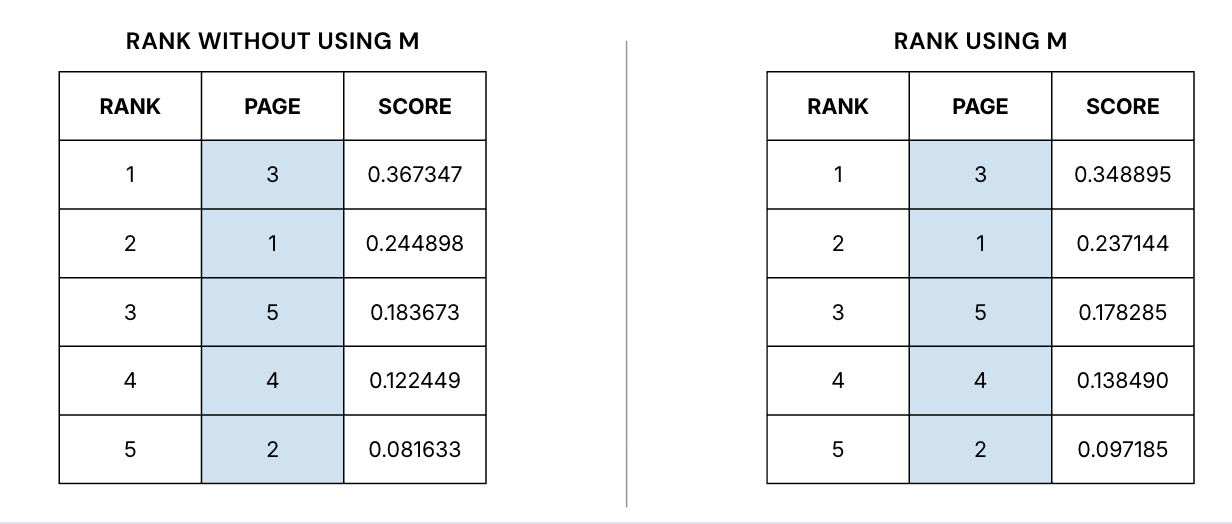

In [ ]:
display(Image(filename='rank_es11.png',width=850, height=400))

## **Exercise 14**

*For the web in Exercise 11, compute the values*
 $|M^k x_0 - q|_1$
*and*
$\frac{|M^k x_0 - q|_1}{|M^{k-1} x_0 - q|_1}$
*for k = 1, 5, 10, 50, using an initial guess $x_0$ not too close to the actual eigenvector $q$. Determine*
$
c = \max_{1 \le j \le n} \left| 1 - 2\min_{1 \le i \le n} M_{ij} \right|
$
*and the absolute value of the second largest eigenvalue of M.
We compute the exact eigenvector $q$ with the "eig" function and compare it with the iterates of the
power method.*

**Approach**

This exercise focuses on the **convergence** properties of the power method when applied to the modified PageRank matrix $M$.

Given an initial vector $x_0$ that is not too close to the dominant eigenvector
$q$, the goal is to analyze how fast the iterates $M^k x_0$ converge to $q$.
This is done by measuring the error in the $\ell_1$ norm and by comparing successive errors.
The exact PageRank vector $q$ is computed using the eig function from the SciPy library on $M$ and normalized in the
$\ell_1$ norm.


**Convergence**

The convergence is evaluated using the quantities

$$
\| M^k x_0 - q \|_1
\quad \text{and} \quad
\frac{\| M^k x_0 - q \|_1}{\| M^{k-1} x_0 - q \|_1},
$$

for different values of $k$.

The first quantity measures the absolute distance between the current iterate
and the exact PageRank vector, while the second one provides an estimate of
the **speed of convergence** of the power method.
From the theory of the power method, the convergence rate is governed by the magnitude of the second largest eigenvalue $|\lambda_2|$ of $M$.

In [ ]:
#Compute exact q just once and normalize it
w_exact, v_exact = np.linalg.eig(M)
dominant_index = np.abs(w_exact - 1.0).argmin()
q_exact = v_exact[:, dominant_index].reshape(-1, 1)
if q_exact[0, 0] < 0: # POSITIVO -> visto che posso ottenere sia il positivo che il negativo porto tutto in positivo
    q_exact = -q_exact
q_exact = q_exact / np.linalg.norm(q_exact, 1) #normalize q_exact using norm 1

#Tutte le norme sono norma 1 -> somma delle componenti del vettore=1

def power_method_analysis(M, k,q_exact):
  """ Function that recieves as innput the matrix M, the number of iterations k, and the exact eigen vector.
      Computes an approximation of the eigenvector in k iterations and compares it with q_exact, by computing the error.
      Returns the error and the speed of convergence.
  """

  n = M.shape[0]
  x0 = np.ones((n, 1)) #initial guess
  vm = x0 / np.linalg.norm(x0,1) #normalize x0
  vm_penultimo= np.ones((n, 1)) #inizializzo per errore

  for m in range(1, k + 1):
    vm1 = M @ vm
    lam1 = (vm.T @ vm1)[0, 0] #(Rayleigh Quotient se usi la norma 2)
    #vm = vm1 / np.linalg.norm(vm1, ord=1) #M column stoc.non cambio la norma 1 se moltiplico
    vm=vm1
    if m==k-1:
      vm_penultimo=vm.copy()

  errore=np.linalg.norm(q_exact - vm,ord=1)
  errore_pre=np.linalg.norm(q_exact - vm_penultimo,ord=1)
  ratio=errore/errore_pre

  return errore,ratio




In [ ]:
for k in [1,5,10,15,25,50,60,71]:
  #we can see the speed of concergence stabilized to 0.611 (|lambda2|) and at iteration 71 we arrive at convergence (error at iteration 70 equal to error at iteration 71)
    print("\n=== k =", k, "===")
    err,ratio = power_method_analysis(M, k, q_exact)
    print('Error last iteration: ', err)
    print('Speed of convergence: ', ratio)


=== k = 1 ===
Error last iteration:  0.22188746624571576
Speed of convergence:  0.05547186656142894

=== k = 5 ===
Error last iteration:  0.03408111322280419
Speed of convergence:  0.5719266399222785

=== k = 10 ===
Error last iteration:  0.0027994812936854435
Speed of convergence:  0.6143626065698039

=== k = 15 ===
Error last iteration:  0.00023891334363591865
Speed of convergence:  0.6111169835311216

=== k = 25 ===
Error last iteration:  1.7402824467604994e-06
Speed of convergence:  0.6112686937561648

=== k = 50 ===
Error last iteration:  7.878073193801072e-12
Speed of convergence:  0.611270177811326

=== k = 60 ===
Error last iteration:  5.748179709996748e-14
Speed of convergence:  0.6129939322184401

=== k = 71 ===
Error last iteration:  2.7755575615628914e-15
Speed of convergence:  1.0


In [ ]:
#lambda 2:
w_exact, v_exact = np.linalg.eig(M) #Not follow the magnitude order
idx_sorted = np.argsort(-np.abs(w_exact)) #order
lambda2 = w_exact[idx_sorted[1]]   # λ2
print("|lambda2| =", np.abs(lambda2)) #|lambda2| is equal to the speed convergence as the paper shows us (from iteration 15 until convergence)


|lambda2| = 0.6112685063651938


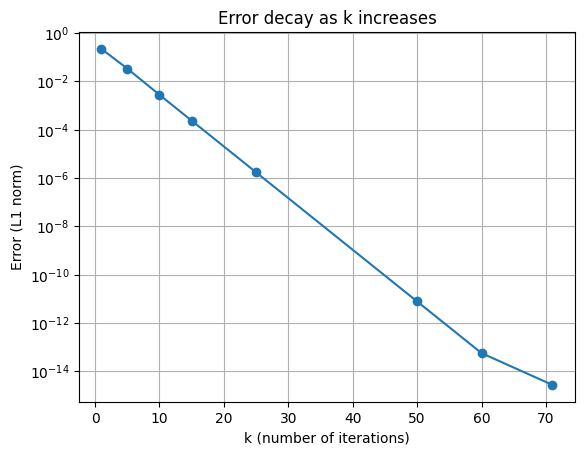

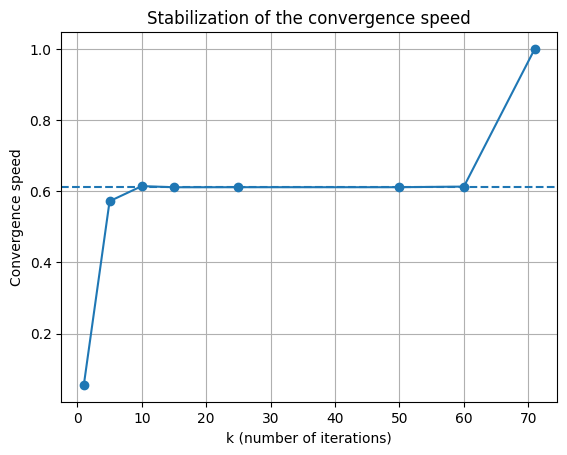

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
k_values = np.array([1, 5, 10, 15, 25, 50, 60, 71])
errors = np.array([0.22188746624571576,0.03408111322280419,0.0027994812936854435,0.00023891334363591865,1.7402824467604994e-06,7.878073193801072e-12,5.748179709996748e-14,2.7755575615628914e-15])
ratios = np.array([0.05547186656142894,0.5719266399222785,0.6143626065698039,0.6111169835311216,0.6112686937561648,0.611270177811326,0.6129939322184401, 1.0])
plt.figure()
plt.plot(k_values, errors, marker='o')
plt.yscale('log')
plt.xlabel("k (number of iterations)")
plt.ylabel("Error (L1 norm)")
plt.title("Error decay as k increases")
plt.grid(True)
plt.show()
plt.figure()
plt.plot(k_values, ratios, marker='o')
plt.axhline(0.6129, linestyle='--')
plt.xlabel("k (number of iterations)")
plt.ylabel("Convergence speed")
plt.title("Stabilization of the convergence speed")
plt.grid(True)
plt.show()

**Results of convergence**
- Between iterations k = 15 e k = 70, the **convergence rate stabilises** around the value of the second-largest eigenvalue, 0.611, as theoretically expected for the power method.
- At iteration k = 71, the algorithm can be considered **converged**: the error at the last iteration
coincides with that of the previous one, indicating that the approximation of the dominant
eigenvector no longer changes

**Upper bound for the convergence speed**

We compute
$$
c = \max_j \bigl|1 - 2 \min_i M_{ij}\bigr|.
$$
and we can see how this number is a general upper-bound for the speed of convergence.

In [ ]:
c = np.max(np.abs(1 - 2 * np.min(M, axis=0)))
print("c =", c)

c = 0.94


Another way to compute an upper-bound for the speed of convergence is $$c = 1-2*m/n$$
Where m=0.15 and n=5 for the matrix M in our exercise.

In [ ]:
print('c = ',1-2*0.15/5)

c =  0.94


We can see how we obtain the same result, cosidering the "worst column of M" the column with all $m/n$ entries.

While the bound $c$ is not tight, it correctly captures the worst-case behavior
of the convergence rate. The actual speed of convergence observed in the power
method is significantly faster and is accurately described by the magnitude
of the second largest eigenvalue of $M$.

____

#**PageRank Algorithm**
In this part we **implement** the PageRank algorithm in order to compute the dominant eigenvector of the link matrix A, which determines the final ranking of the pages.

We first apply the algorithm on a real large database (Hollins.dat) and then on the two Figures of the
paper.

##Power Method

The most suitable technique to approximate the dominant eigenvector is the power method: starting from an initial score vector, the method applies the link matrix repeatedly and normalises the output at each
step. Once the updates no longer changes the vector appreciably, the iteration has converged, and the resulting vector is an **approximation of the dominant eigenvector**.

To prived a unique rank in case of subwebs, the update performed at each step takes the form

$$x^{(k+1)}= (1 − m)A x^{(k)} + mS x^{(k)}$$
which is simply the power method applied to the matrix $M$.

**Dangling Nodes Problem**

However, in real web graphs such as the Hollins dataset, the main obstacle is the presence of dangling nodes, i.e. **pages with no outgoing links**, which appear
as zero columns in A.
Such columns cause the iteration to accumulate score on these pages rather
than converge to a meaningful vector, and therefore require an explicit correction in the update rule.


##**1)Hollins Dataset**
The Hollins dataset consists of **6012 nodes**, each representing a web page, and a set of **directed edges** corresponding to hyperlinks between pages.

A key characteristic of the dataset is the presence of a large number of **dangling nodes**, i.e. pages with no outgoing links. In total, **3189 nodes** fall into this category, accounting for more than half of the total number of pages.

**Sparse Storage Format**

The link matrix $A$ is stored using the **Compressed Sparse Row (CSR)** format. This choice is motivated by the extreme sparsity of the matrix and by the fact that the dominant operation involving $A$ is **matrix–vector multiplication**.

Matrix $A$ has a sparsity of **99.934\%** (equivalently, a density of **0.066\%**), meaning that only a very small fraction of its entries are non-zero. Exploiting this sparsity is essential to reduce both memory usage and computational cost.


During matrix–vector multiplication, **each row of $A$ is processed by accessing only its non-zero entries**. This approach avoids unnecessary operations on zero entries and enables an efficient implementation.



###Update Correction

- **Correcting dangling nodes**

A natural approach would be to modify the matrix $A$ by replacing each zero column with a uniform column whose entries are all equal to **$1/n$**.

This corresponds to assuming that, when a page has no outgoing links, a surfer can **move to any page** with equal probability.

However, this modification would make $A$ **dense**, destroying sparsity and
significantly increasing the computational cost for large graphs.

To avoid this, a **correction matrix $D$** could be constructed containing 1/n in the columns associated with dangling
nodes and all zeros in the remaining columns.

However, since **all rows of D would be identical** by construction, constructing the full matrix D offers no advantage
and we only store an indicator vector $d$ be an indicator vector such that

$$
d_j =
\begin{cases}
1/n & \text{if node } j \text{ is dangling},\\
0 & \text{otherwise}
\end{cases}
$$


The uniform redistribution of the probability associated with dangling nodes can then be efficiently
incorporated through the term

$$
(1 - m)\,(d^\top x^{(k)})\,\mathbf{1},
$$

which is algebraically equivalent to applying the full correction matrix $D$ but
preserves sparsity of $A$.



- **Correcting subwebs**

A similar simplification applies to the teleportation matrix $S$, which is **dense** and has all entries equal to $1/n$; all its rows are identical. Rather than using the full matrix $S$, it would be sufficient to use a single row vector whose entries are all equal to $1/n$.

Let $s$ denote this row vector. Multiplying $s$ by the PageRank iterate $x^{(k)}$ gives
$$
s\,x^{(k)} = \frac{1}{n}\sum_{i=1}^n x_i^{(k)}.
$$

Since the power method preserves the normalization
$$
\|x^{(k)}\|_1 = \sum_{i=1}^n x_i^{(k)} = 1,
$$
we obtain
$$
s\,x^{(k)} = \frac{1}{n}.
$$

Therefore, the product $Sx^{(k)}$ reduces to a constant vector whose entries are all equal to $1/n$, and the contribution of the teleportation term can be incorporated by simply adding
$$
\frac{m}{n}\mathbf{1},
$$
without explicitly constructing the dense matrix $S$.


### **Final update rule**

Combining the propagation through the actual links with the dangling–node
correction and the teleportation contribution leads to the update rule used in
our implementation:

$$
x^{(k+1)} = (1 - m)\,A x^{(k)} + (1 - m)\,(d^\top x^{(k)})\,\mathbf{1}
           + \frac{m}{n}\,\mathbf{1}.
$$

This formulation avoids the construction of large dense matrices, preserves
the sparsity of $A$, and guarantees convergence even in the presence of
dangling nodes and subwebs.

**Computational cost**

At each iteration of the power method, the dominant computational cost comes from the **link propagation term**, which requires a sparse matrix–vector multiplication. Since $A$ is stored in CSR format, only the non-zero entries are accessed during the computation. Therefore, the cost of a single matrix–vector product is proportional to the maximum number of non-zero elements in a row of the $A$ matrix ($N_r$), and can be bounded by
$$O(\mathrm{N_r} * n)$$
which is significantly lower than the $O(n^2)$ cost associated with dense matrices.

The remaining terms of the PageRank update, which account for dangling nodes and teleportation, have linear complexity in $n$ and are therefore negligible compared to the sparse matrix–vector multiplication.

As a result, the per-iteration computational complexity of the algorithm is $$O(\mathrm{N_r} * n)$$
Since the power method requires $k$ iterations to converge, the overall computational complexity of the PageRank computation is:

$$O(k*N_r*n)$$






In [ ]:
def read_file(filename):
    """
    Function built to read hollins.dat file and extract useful information.
    Returns: N, urls, sources, destinations
    """
    with open(filename, "r", encoding="utf-8") as f:
        # 1) First line: N, M --> N is the number of pages and M the number of links
        first_line = f.readline().split()
        N, M = map(int, first_line)

        # 2) Next N lines: (id, url) --> they are the nodes
        urls = {}  # dictionary {id: url}
        for n in range(N):
            line = f.readline().rstrip("\n")
            if not line:
                continue
            parts = line.split()
            node_id = int(parts[0]) - 1
            url = " ".join(parts[1:])
            urls[node_id] = url

        # 3) Next M lines: links (u, v)
        sources = np.empty(M, dtype=int)
        destinations = np.empty(M, dtype=int)
        k = 0

        for line in f:
            line = line.strip()
            if not line:
                continue
            u, v = map(int, line.split())
            sources[k] = u - 1
            destinations[k] = v - 1
            k += 1

        # In case fewer than M links are actually present
        if k < M:
            sources = sources[:k]
            destinations = destinations[:k]

    return N, urls, sources, destinations

In [ ]:
N,urls,sources,destinations=read_file("/content/hollins.dat")

In [ ]:
from scipy.sparse import csr_matrix, diags

def build_link_matrix(N, sources, destinations):
    """
    Build the link matrix A directly from the lists of sources and destinations.
    For each page j, column j of A contains the probability of transitioning
    from page j to every page it links to:
        A[i, j] = 1 / (number of outgoing links from j)   if j → i
        A[i, j] = 0                                       otherwise
    """
    # Destination nodes: pages receiving a link (i)
    # Source nodes: pages where the link originates (j)
    # Each directed edge is represented by the coordinate (row[k], col[k]).
    row = destinations
    col = sources

    # Each observed edge contributes a value of 1 in the adjacency matrix
    data = np.ones(len(row), dtype=float)


    #DOBBBIAMO FARLA IN CSR PERCHè è OTTIMIZZATO PER IL PRODOTTO

    adj_M = csr_matrix((data, (row, col)), shape=(N, N))
    nnz = adj_M.nnz              # numero di elementi non nulli
    total = N * N                # elementi totali
    density = nnz / total        # densità
    sparsity = 1 - density       # sparsità
    print('number of non-zeros=', nnz)
    print('density_perc =' , 100 * density)
    print('sparsity_perc = ', 100 * sparsity)


    #now that I have the adjacecny matrix, I want to weigh the votes depending on how many pages a certain page links to (how many outgoing edges does it have)

    # Count the number of outgoing links for each page j by summing column j.
    num_archi_uscenti =  np.asarray(adj_M.sum(axis=0)).flatten() # shape (N,) --> vector of scalars that indicate the number of outgoing edges from the j-th node

    # Now we want each column of A to sum to 1: we normalize column j by dividing it by num_outgoing[j]. To do this in a vectorized way, we use the property that
    # right-multiplying a matrix by a diagonal matrix scales its columns.
    # We therefore build a diagonal matrix with 1 / num_outgoing[j] on the diagonal (D_inv) and compute the normalized matrix as: adj_Matrix @ D_inv
    #However if there are dangling nodes, we don't tant to divide by 0 so we first identify them and temporarly substitute zeros with ones
    dangling = (num_archi_uscenti == 0)
    num_archi_uscenti_safe = num_archi_uscenti.copy()
    num_archi_uscenti_safe[dangling] = 1

    D_inv = diags(1.0 / num_archi_uscenti_safe)
    A = adj_M @ D_inv
    return A


In [ ]:
A= build_link_matrix(N, sources, destinations)

number of non-zeros= 23875
density_perc = 0.06605496038307063
sparsity_perc =  99.93394503961693


In [ ]:
print("Sum along columns:", A[:, :].toarray().sum(axis=0))  #to see if there are dangling nodes

Sum along columns: [1. 1. 0. ... 0. 0. 0.]


We observe that there are some dangling nodes, and therefore A is not column-stochastic.

In [ ]:
#creation of d_vector:col_sums = A.sum(axis=0)
cols_sums=A[:, :].toarray().sum(axis=0)
zero_cols_mask = (cols_sums == 0)  # mask: True where the column sums 0
d_vettore= zero_cols_mask.astype(int)*1/N
print(f"1/n = {1/N}")
print(f"Indicator vector for dangling nodes:\n{d_vettore}")
print(d_vettore.shape)

1/n = 0.00016633399866932801
Indicator vector for dangling nodes:
[0.         0.         0.00016633 ... 0.00016633 0.00016633 0.00016633]
(6012,)


In [ ]:
import math
def power_method(A,d_vettore,maxIter,tol,m=0.15):
  n = A.shape[0]
  x0 = np.ones((n, 1))
  xk = x0 / np.linalg.norm(x0,1)
  lam=math.inf

  for k in range(maxIter):
    # at each iteration I compute and combine the three terms a,b,c --> new update xk1=a+b+c

    #First term: link propagation
    a=(1-m)*(A@xk)

    #Second term: dangling correction
    # d_vector has shape (1, N), xk has shape (N, 1)
    b=(1-m)*(d_vettore @ xk) # d_vector @ xk calculates the sum of PageRank scores for dangling nodes, resulting in a (1,1) matrix


    #Third term: teleportation
    c=m*1/n*(1)
    #xk.sum()= 1 perchè e normalizzato in norma 1

    #UPDATE:
    xk1=a+b+c #sum of the 3 terms
    lam1=(xk.T@xk1)/(np.linalg.norm(xk))**2 #-->lambda
    #xk1=xk1/np.linalg.norm(xk1,1)  #normalization using norm1
    xk=xk1/np.linalg.norm(xk1,1)

    if np.abs(lam1 - lam) < tol * np.abs(lam1):
        print(f"Convergence reached in {k+1} iterations")
        break
    else:
        lam = lam1;


    #if np.linalg.norm(xk1 - xk, 1) < tol:
      #print(f"Convergence reached in {k+1} iterations")
      #break
    #xk = xk1

  return xk1,lam1,k

In [ ]:
autovett,autoval,k=power_method(A,d_vettore,3000,1e-10)


Convergence reached in 106 iterations


In [ ]:
print(autoval)

[[1.]]


In [ ]:
print_ranking("PageRank - Hollins dataset (Top 20 Pages)", autovett, pages=np.arange(1, N+1), urls=urls, top=20)


PageRank - Hollins dataset (Top 20 Pages)
--------------------------------------------------------------------------------
Rank   Page   Score        URL
--------------------------------------------------------------------------------
1      2      0.019879     http://www.hollins.edu/
2      37     0.009288     http://www.hollins.edu/admissions/visit/visit.htm
3      38     0.008610     http://www.hollins.edu/about/about_tour.htm
4      61     0.008065     http://www.hollins.edu/htdig/index.html
5      52     0.008027     http://www.hollins.edu/admissions/info-request/info-request.cfm
6      43     0.007165     http://www.hollins.edu/admissions/apply/apply.htm
7      425    0.006583     http://www.hollins.edu/academics/library/resources/web_linx.htm
8      27     0.005989     http://www.hollins.edu/admissions/admissions.htm
9      28     0.005572     http://www.hollins.edu/academics/academics.htm
10     4023   0.004452     http://www1.hollins.edu/faculty/saloweyca/clas%20395/Sculpture

**Results**

The resulting ranking is stable and consistent, indicating
that the adopted modifications successfully handle the structural properties of the graph.

Furthermore, the ranking shows a **pattern** that is typical of real-world university websites. The **top** pages all correspond to highly connected, **central sections** of the website such as the
*homepage, admissions pages, and academic program pages*. These pages serve as major entry points
and tend to receive a large number of incoming links from the rest of the website, which naturally
increases their PageRank score.


---

##**2) PageRank on Fig 2.1**
We then applied the algorithm to the small web graph shown in Figure 2.1, which had the folowing structure

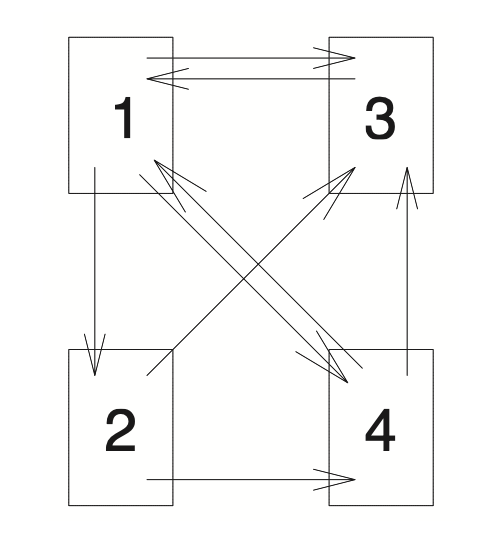

In [ ]:
display(Image(filename='Fig_2_1.png', width=300, height=300))

In [ ]:
A_2_1 = np.array([
    [0.0, 0.0, 1, 1/2],
    [1/3, 0.0, 0.0, 0.0],
    [1/3, 1/2, 0.0, 1/2],
    [1/3, 1/2, 0.0, 0.0]
])

col_sums = A_2_1.sum(axis=0)
zero_cols_mask = (col_sums == 0)
c_vettore= zero_cols_mask.astype(int)
#calcolo il rank
autovett,autoval=power_method(A_2_1,c_vettore,100,1e-10)
print_ranking("PageRank - Fig 2.1", autovett, pages=np.arange(1,5))



PageRank - Fig 2.1
----------------------------------------------
Rank   Page   Score       
----------------------------------------------
1      1      0.368151    
2      3      0.287962    
3      4      0.202078    
4      2      0.141809    
----------------------------------------------


**Results**

Page 1 receives the largest score, consistently with the fact that several ”important”
pages point to it.
As the ranking shows, the result obtained with our corrected power method matches the ordering
presented in exercise 1 as *original rank*, which was computed by directly evaluating the dominant eigenvector of the link matrix.

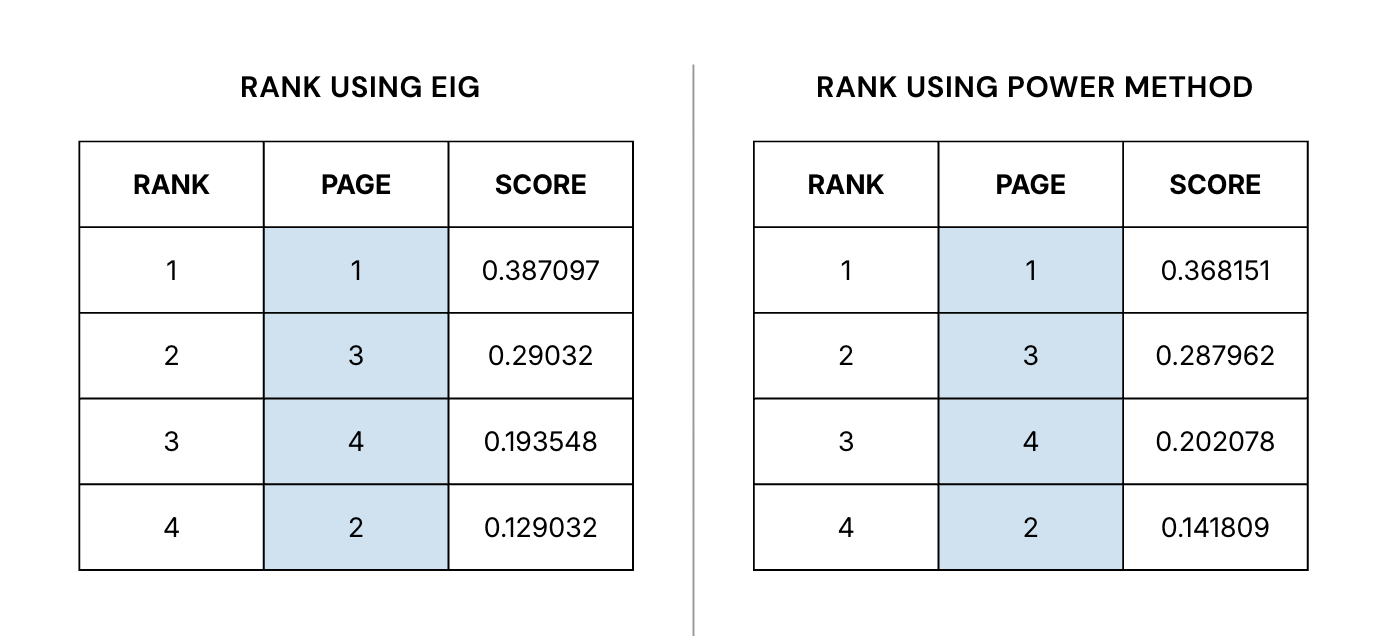

In [ ]:
display(Image(filename='Rank_2_1_Power.png', width=700, height=350))

---

##**3) PageRank on Fig 2.2**
Finally, we applied our PageRank implementation to the graph shown in Figure 2.2 of the paper, that
contained a **subweb**

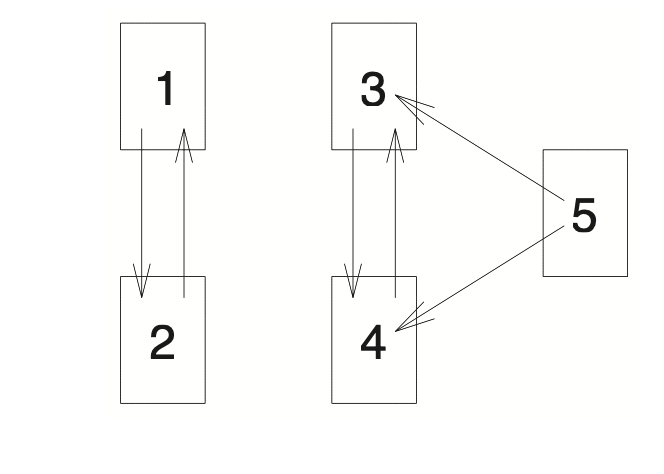

In [ ]:
display(Image(filename='Fig_2_2.png', width=400, height=300))

In [ ]:
A_2 = np.array([
    [0.0, 1.0, 0.0, 0.0,0.0],
    [1, 0.0, 0.0, 0.0,0.0],
    [0.0, 0.0,0.0, 1, 1/2],
    [0.0, 0.0, 1.0, 0.0,1/2],
    [0.0, 0.0, 0.0, 0.0,0.0],
])

col_sums = A_2.sum(axis=0)
zero_cols_mask = (col_sums == 0)
c_vettore= zero_cols_mask.astype(int)
#calcolo il rank
autovett,autoval=power_method(A_2,c_vettore,100,1e-10)
print_ranking("PageRank on Fig 2.2", autovett, pages=np.arange(1,6))



PageRank on Fig 2.2
----------------------------------------------
Rank   Page   Score       
----------------------------------------------
1      3      0.285000    
2      4      0.285000    
3      1      0.200000    
4      2      0.200000    
5      5      0.030000    
----------------------------------------------


**Results**

As we can observe from the graph, **pages 3 and 4** form a **subweb**, they point to one another and also
receive additional incoming links from page 5. This closed linking structure allows them to **reinforce** each other, and the ranking produced by our method assigns them the highest scores, as expected.

**Pages 1 and 2** also link to one another, but unlike the subweb they **do not receive any links from outside **their two–node component. Their scores are therefore lower than those of pages 3 and 4, but remain higher than the score of page 5.

Finally, **page 5** has only outgoing links and **no incoming** ones, so it receives the smallest ranking value.
